In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Data Loading

In [4]:
amazon_data =  pd.read_csv('amz_uk_price_prediction_dataset.csv')
amazon_df = amazon_data.copy()

In [6]:
#Shape of the data
amazon_df.shape

(2443651, 9)

In [8]:
#Null Check
amazon_df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [10]:
#Check Datatypes
amazon_df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [12]:
amazon_df.head(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [14]:
#Remove Duplicates and check shape again
amazon_df = amazon_df.drop_duplicates(keep='first')
amazon_df.shape

(2443651, 9)

# Part 1: Understanding Product Categories

Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

Frequency Tables:

Generate a frequency table for the product category.
Which are the top 5 most listed product categories?
Visualizations:

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [16]:
cat_freq_df = amazon_df.category.value_counts()
cat_freq_prop_df = amazon_df.category.value_counts(normalize=True)
cat_freq_df = pd.concat([cat_freq_df,cat_freq_prop_df],axis=1).reset_index()

#Sort and pick top 5 products
cat_freq_df = cat_freq_df.sort_values(by='count',ascending=False).head(5)\
                                                                 .reset_index(drop=True)
cat_freq_df

,category,count,proportion
0,Sports & Outdoors,836265,0.342219
1,Beauty,19312,0.007903
2,"Handmade Clothing, Shoes & Accessories",19229,0.007869
3,Bath & Body,19092,0.007813
4,Birthday Gifts,18978,0.007766


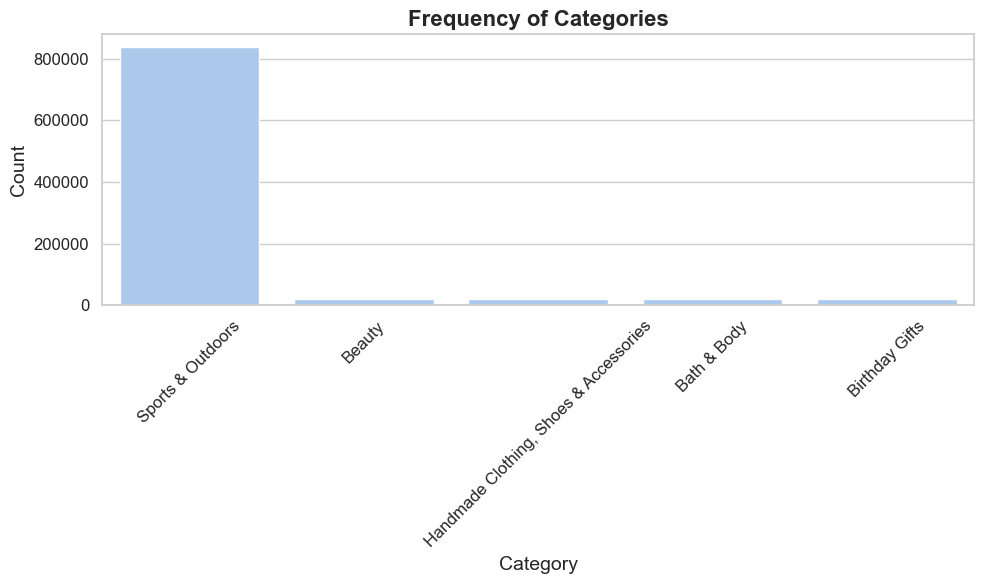

In [17]:
# Set the style and color palette
sns.set_theme(style="whitegrid", palette="pastel")

# Create the bar plot
plt.figure(figsize=(10, 6))
sns.barplot(data=cat_freq_df, x='category', y='count', errorbar=None)

# Add title and labels
plt.title('Frequency of Categories', fontsize=16, fontweight='bold')
plt.xlabel('Category', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Enhance readability
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()

# Show the plot
plt.show()

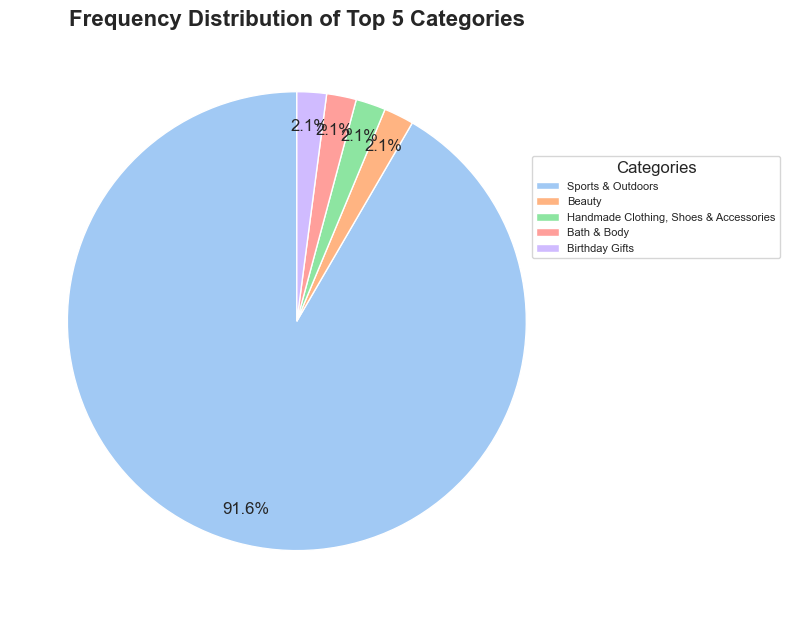

In [18]:
# Create the pie chart without labels
plt.figure(figsize=(8, 8))
wedges, texts, autotexts = plt.pie(
    cat_freq_df['count'],
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette("pastel", len(cat_freq_df['category'])),
    textprops={'fontsize': 12},
    pctdistance=0.85  # Adjust position of percentage text
)

# Add a legend with the category names
plt.legend(
    wedges,
    cat_freq_df['category'],
    title="Categories",
    loc="lower left",
    bbox_to_anchor=(0.9, 0.6),
    fontsize=8
)

# Add a title
plt.title('Frequency Distribution of Top 5 Categories', fontsize=16, fontweight='bold')

# Show the plot
plt.tight_layout()
plt.show()

Sports & Outdoors dominate the product category with 34.2% of all categories and among top 5 it holds 92% of the top 5 categories

# Part 2: Delving into Product Pricing

Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

Measures of Centrality:

Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?
Measures of Dispersion:

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?
Visualizations:

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [25]:
basic_stats = amazon_df[['price']].describe().map("{:,.1f}".format)
basic_stats

,price
count,"2,443,651.0"
mean,89.2
std,345.6
min,0.0
25%,10.0
50%,19.1
75%,46.0
max,"100,000.0"


In [27]:
#Mode of the prices
amazon_df[['price']].mode()

,price
0,9.99


From the table above we can see the mean is 89.2, the median is 19.1, and the most frequent price is 9.99. 
**Relationship : mean > median > mode**

In [30]:
#Variance, Standard Deviation, Range, IQ Range
print("Variance : {}".format(round(amazon_df.price.var(),1)))
print("SD : {}".format(round(amazon_df.price.std(),1)))
print("Range : {}".format(round(amazon_df.price.max() - amazon_df.price.min(),1)))
print("IQ : {}".format(amazon_df.price.quantile(q=0.75)- amazon_df.price.quantile(q=0.25)))
print("95% Percentile : {}".format(amazon_df.price.quantile(q=0.95)))
print("99% Percentile : {}".format(amazon_df.price.quantile(q=0.99)))

Variance : 119445.5
SD : 345.6
Range : 100000.0
IQ : 36.0
95% Percentile : 349.5
99% Percentile : 1408.82


There is significant difference between the IQR and the Range so it would be interesting to show it in a box plot to see how the spread is. Till 75% the prices are not changing that much and fall below 46. 95% of the price point is below 349.5

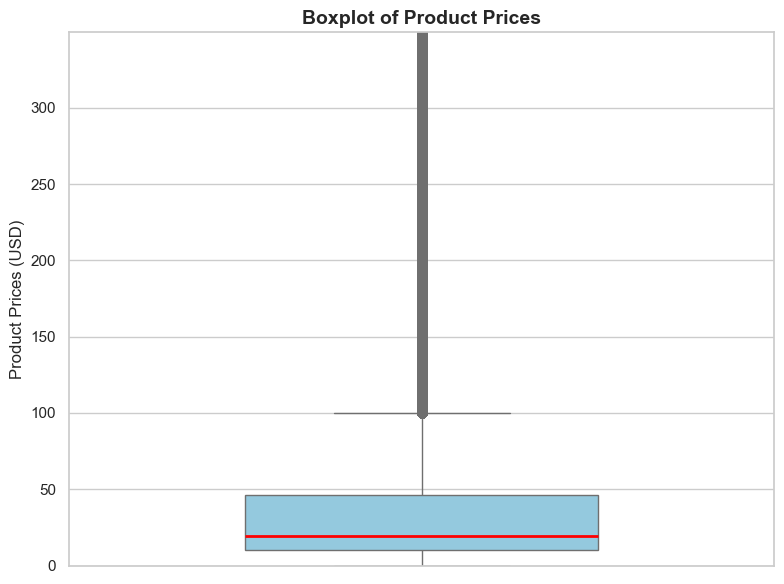

In [33]:
# Create a figure with one subplot for the boxplot
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

# Boxplot
sns.boxplot(
    data=amazon_df,
    y='price',
    ax=ax,
    color='skyblue',
    width=0.5,
    medianprops={"color": "red", "linewidth": 2},  # Custom median line
)

# Set the title and labels
ax.set_title("Boxplot of Product Prices", fontsize=14, fontweight="bold")
ax.set_ylabel("Product Prices (USD)")

# Adjust the y-axis scale (optional)
ax.set_ylim(0, amazon_df['price'].quantile(0.95))  # Adjust upper limit to 95th percentile

# Improve layout
plt.tight_layout()
plt.show()

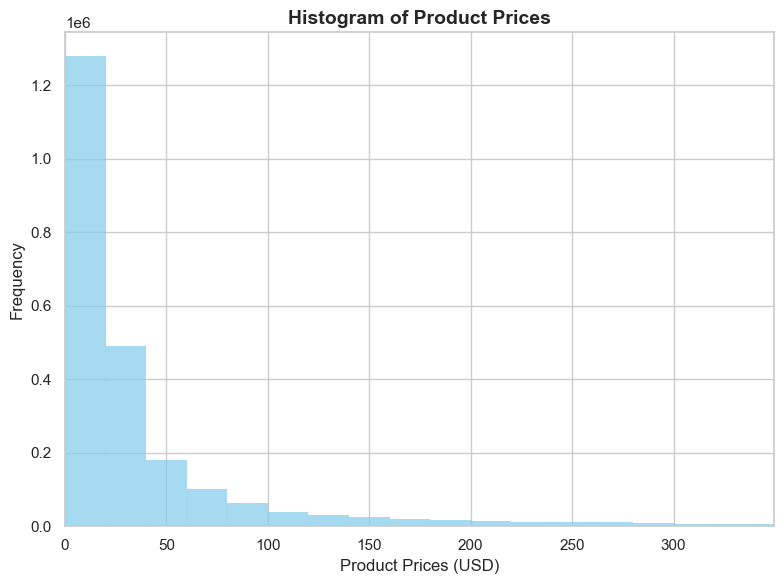

In [34]:
# Create a figure for the histplot
fig, ax = plt.subplots(figsize=(8, 6))

# Histplot
sns.histplot(
    amazon_df['price'],
    #kde=True,  # Add a kernel density estimate for smoother distribution curve
    bins=5000,   # Adjust the number of bins as needed
    color='skyblue',
    edgecolor='black',
    ax=ax
)

# Set the title and labels
ax.set_title("Histogram of Product Prices", fontsize=14, fontweight="bold")
ax.set_xlabel("Product Prices (USD)")
ax.set_ylabel("Frequency")

# Adjust the x-axis scale for better visibility (optional)
ax.set_xlim(0, amazon_df['price'].quantile(0.95))  # Set x-limits to 95th percentile to avoid extreme values

# Improve layout
plt.tight_layout()
plt.show()

This histogram shows 95% of the dataset and its positively (right) skewed distribution

In [37]:
IQR = amazon_df.price.quantile(q=0.75) - amazon_df.price.quantile(q=0.25)
lower = amazon_df.price.quantile(q=0.25) - 1.5 * IQR
upper = amazon_df.price.quantile(q=0.75) + 1.5 * IQR


#Clean outliers from the dataset
clean_df = amazon_df[(amazon_df['price'] >= lower) & (amazon_df['price'] <= upper)]
outlier_df = amazon_df[(amazon_df['price'] < lower) | (amazon_df['price'] > upper)]

print("Number of rows with outliers : {}".format(len(outlier_df)))
print("Number of rows without outliers : {}".format(len(clean_df)))

Number of rows with outliers : 327688
Number of rows without outliers : 2115963


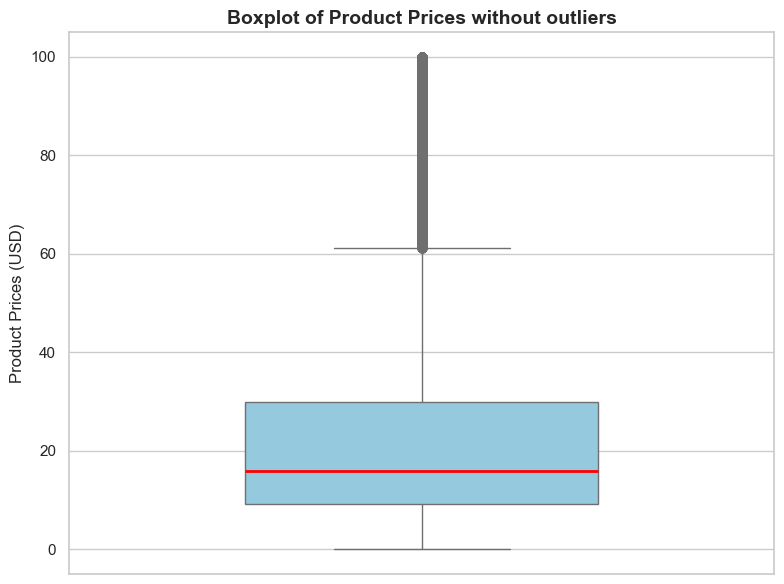

In [40]:
# Create a figure with one subplot for the boxplot
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

# Boxplot
sns.boxplot(
    data=clean_df,
    y='price',
    ax=ax,
    color='skyblue',
    width=0.5,
    medianprops={"color": "red", "linewidth": 2},  # Custom median line
)

# Set the title and labels
ax.set_title("Boxplot of Product Prices without outliers", fontsize=14, fontweight="bold")
ax.set_ylabel("Product Prices (USD)")

# Adjust the y-axis scale (optional)
#ax.set_ylim(0, amazon_df['price'].quantile(0.95))  # Adjust upper limit to 95th percentile

# Improve layout
plt.tight_layout()
plt.show()

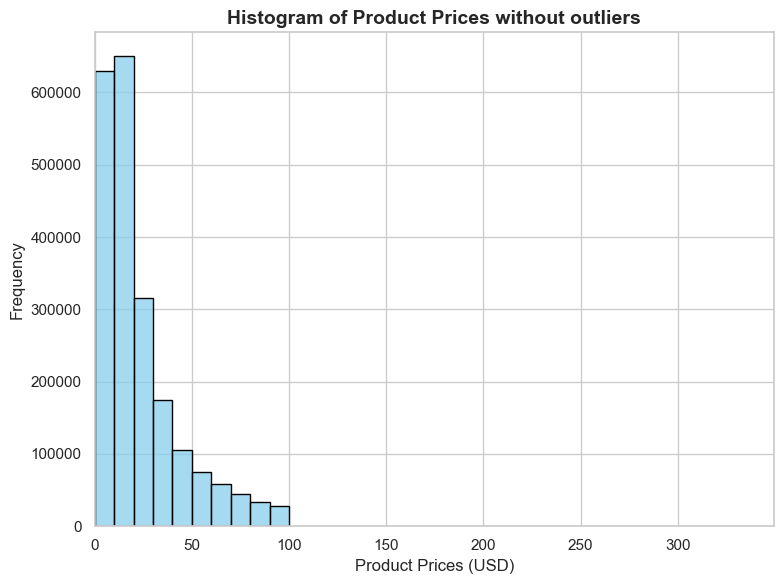

In [42]:
# Create a figure for the histplot
fig, ax = plt.subplots(figsize=(8, 6))

# Histplot
sns.histplot(
    clean_df['price'],
    #kde=True,  # Add a kernel density estimate for smoother distribution curve
    bins=10,   # Adjust the number of bins as needed
    color='skyblue',
    edgecolor='black',
    ax=ax
)

# Set the title and labels
ax.set_title("Histogram of Product Prices without outliers", fontsize=14, fontweight="bold")
ax.set_xlabel("Product Prices (USD)")
ax.set_ylabel("Frequency")

# Adjust the x-axis scale for better visibility (optional)
ax.set_xlim(0, amazon_df['price'].quantile(0.95))  # Set x-limits to 95th percentile to avoid extreme values

# Improve layout
plt.tight_layout()
plt.show()

In [43]:
clean_basic_stats = clean_df[['price']].describe().map("{:,.1f}".format)
clean_basic_stats

,price
count,"2,115,963.0"
mean,23.4
std,20.5
min,0.0
25%,9.1
50%,16.0
75%,30.0
max,100.0


After removing outliers its clear that the majority of the prices range falls between 0 to 100

In [47]:
#Checking the products with the prices higher 0.99998% than the rest of the outliers
outlier_df[['title','category','price']][outlier_df['price'] > outlier_df.price.quantile(q=0.99998)]

,title,category,price
319555,HEDUSA Halloween 3D Holographic Fan 3D Hologra...,Projectors,22933.42
1408966,BM4445-FI1-01200R10-03-E03 Driver,Scanners & Accessories,23482.73
1490285,YXHUI Kids Girls Figure Skating Dress Long Sle...,Sports & Outdoors,21999.00
1490286,YXHUI Kids Girls Figure Skating Dress Long Sle...,Sports & Outdoors,21999.00
1905315,Abaodam decor christmas ornaments Desk Ornamen...,Garden Storage & Housing,24674.59
1987238,Générique L.A 350° - I5 11400F - RTX 3050 8G -...,Desktop PCs,77752.00
2008013,HB FBA Test Treadmill,Sports & Outdoors,100000.00


# Part 3: Unpacking Product Ratings

Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?
Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?
Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?
Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [50]:
stars_stats = amazon_df[['stars']].describe().map("{:,.2f}".format)
stars_stats

,stars
count,"2,443,651.00"
mean,2.15
std,2.19
min,0.00
25%,0.00
50%,0.00
75%,4.40
max,5.00


In [52]:
amazon_df[['stars']].mode()

,stars
0,0.0


In [54]:
#Variance, Standard Deviation, Range, IQ Range of Ratings
print("Variance : {}".format(round(amazon_df.stars.var(),1)))
print("SD : {}".format(round(amazon_df.stars.std(),1)))
print("Range : {}".format(round(amazon_df.stars.max() - amazon_df.stars.min(),1)))
print("IQ : {}".format(amazon_df.stars.quantile(q=0.75)- amazon_df.stars.quantile(q=0.25)))
print("95% Percentile : {}".format(amazon_df.stars.quantile(q=0.95)))
print("99% Percentile : {}".format(amazon_df.stars.quantile(q=0.99)))
print("Skewness : {}".format(amazon_df.stars.skew().round(3)))
print("Kurtosis : {}".format(amazon_df.stars.kurt().round(3)))

Variance : 4.8
SD : 2.2
Range : 5.0
IQ : 4.4
95% Percentile : 5.0
99% Percentile : 5.0
Skewness : 0.081
Kurtosis : -1.926


### Since the Kurtosis < 0 (platykurtic): The distribution has lighter tails and a flatter peak than a normal distribution.

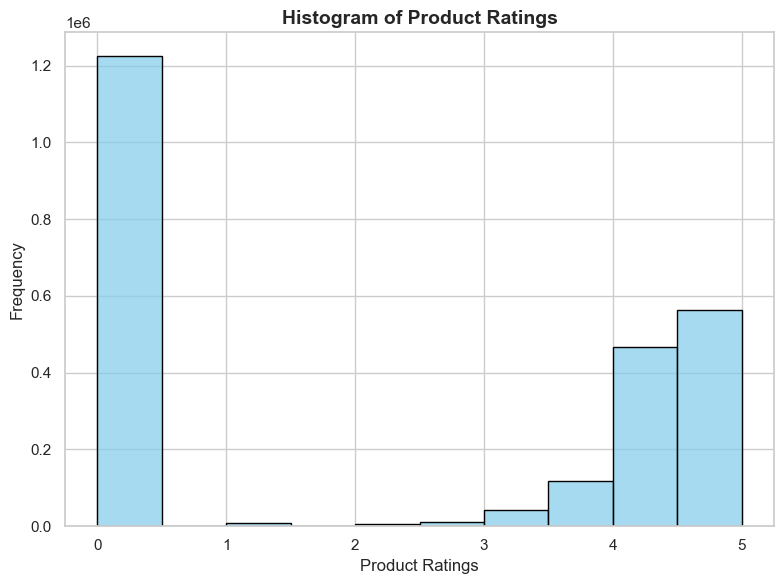

In [57]:
# Create a figure for the histplot
fig, ax = plt.subplots(figsize=(8, 6))

# Histplot
sns.histplot(
    amazon_df['stars'],
    #kde=True,  # Add a kernel density estimate for smoother distribution curve
    bins=10,   # Adjust the number of bins as needed
    color='skyblue',
    edgecolor='black',
    ax=ax
)

# Set the title and labels
ax.set_title("Histogram of Product Ratings", fontsize=14, fontweight="bold")
ax.set_xlabel("Product Ratings")
ax.set_ylabel("Frequency")

# Adjust the x-axis scale for better visibility (optional)
#ax.set_xlim(0, amazon_df['stars'].quantile(0.95))  # Set x-limits to 95th percentile to avoid extreme values

# Improve layout
plt.tight_layout()
plt.show()

- Most Common Product Rating is 0
- Avg. Rating of all the products are 2.3

## Top 10 Product Categories based on Avg. Product Ratings

In [61]:
stars_per_category = amazon_df[['category','stars']].groupby('category').mean().map("{:,.2f}".format).reset_index()

# 10 Product Categories based on avg product ratings
top_10 = stars_per_category.sort_values(by='stars', ascending = False).head(10).reset_index(drop=True)
top_10

,category,stars
0,Luxury Food & Drink,4.55
1,Grocery,4.47
2,Laptop Accessories,4.45
3,Health & Personal Care,4.44
4,Arts & Crafts,4.43
5,Office Paper Products,4.43
6,Customers' Most Loved,4.41
7,"Water Coolers, Filters & Cartridges",4.36
8,USB Hubs,4.36
9,Cables & Accessories,4.34


In [63]:
# Select the data for the top 10
top10_df = amazon_df[amazon_df['category'].isin(top_10.category.to_list())]

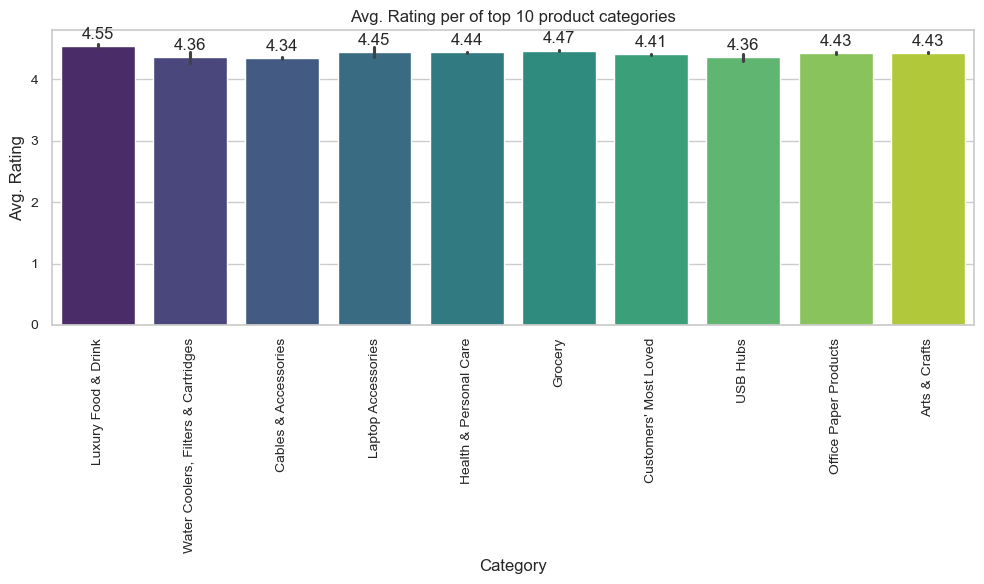

In [65]:
# Create the bar plot
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='category', y='stars',data=top10_df, 
                 hue='category', palette='viridis', legend=False)

# Add value labels on top of the bars
for bar in ax.containers:
    ax.bar_label(bar, fmt='%.2f', label_type='edge', padding=3)

# Customize the plot
plt.title("Avg. Rating per of top 10 product categories")
plt.xlabel("Category")
plt.ylabel("Avg. Rating")

# Enhance readability
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.xticks(rotation=90)

plt.tight_layout()

# Show the plot
plt.show()

## Bottom 10 Product Categories based on Avg. Product Ratings

In [68]:
#Bottom 10 Product Categories based on avg product ratings
bottom_10 = stars_per_category.sort_values(by='stars', ascending = False).tail(10).reset_index(drop=True)

In [70]:
# Select the data for the top 10
bottom10_df = amazon_df[amazon_df['category'].isin(bottom_10.category.to_list())]

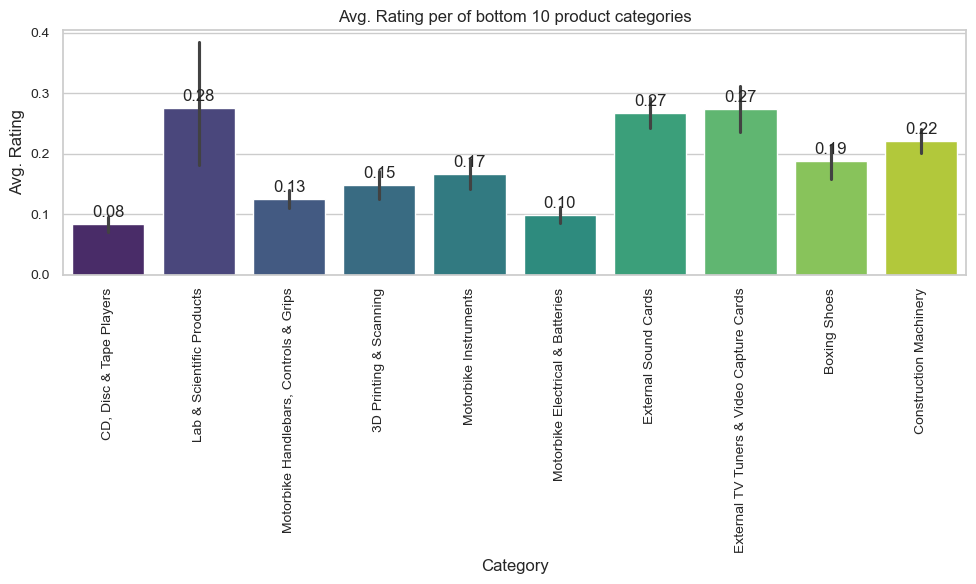

In [72]:
# Create the bar plot
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='category', y='stars',data=bottom10_df, 
                 hue='category', palette='viridis', legend=False)

# Add value labels on top of the bars
for bar in ax.containers:
    ax.bar_label(bar, fmt='%.2f', label_type='edge', padding=3)

# Customize the plot
plt.title("Avg. Rating per of bottom 10 product categories")
plt.xlabel("Category")
plt.ylabel("Avg. Rating")

# Enhance readability
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.xticks(rotation=90)

plt.tight_layout()

# Show the plot
plt.show()